# Question 2 — Height–Weight Relationship and Prediction

**Local JupyterLab notebook (no Colab, no scikit-learn).** Open this notebook from your repository folder and choose **Kernel → Restart Kernel and Run All Cells**.

**Research question:** Does the height–weight relationship differ across sports archetypes after accounting for sex?

This analysis includes descriptive correlation, baseline and multiple linear regression, an **interaction F-test** for the central research question, residuals and Q–Q plots, an athlete-grouped 80:20 split, and individual 95% prediction intervals. It does **not** use cluster-robust inference, AIC/BIC, MAE/RMSE/test R², bootstrap methods, or other formal tests.

In [1]:
# Load the libraries used for the analysis and create folders for the results.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from IPython.display import display

OUTPUT_DIR = Path('q2_outputs')
PLOT_DIR = OUTPUT_DIR / 'plots'
PLOT_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid')

## 1. Load the local dataset

`q1_working` contains the event-level archetype assignments established in Question 1. Combine events by `(ID, Year)` while preserving athletes that participated in multiple years. Records with two distinct archetypes are labelled `MULTIPLE_ARCHETYPES` and are excluded **only** from extended archetype-specific modelling.

In [2]:
# Find the available Q1/Q2 data file and check that the required columns are present.
candidates = [Path('q1_working.csv'), Path('q1_working(1).csv'),
              Path('q2_athlete_year_level.csv')]
source = next((p for p in candidates if p.is_file()), None)
if source is None:
    raise FileNotFoundError(
        'Put q1_working.csv (or q1_working(1).csv) in the folder containing this notebook.'
    )
raw = pd.read_csv(source)
required = {'ID', 'Year', 'Height', 'Weight', 'Sex', 'Archetype'}
missing = required - set(raw.columns)
if missing:
    raise ValueError(f'Missing columns in {source}: {sorted(missing)}')

# Remove incomplete records and keep the athlete-year order consistent.
raw = raw.dropna(subset=list(required)).copy()
raw['Archetype'] = raw['Archetype'].astype(str).str.strip()
raw = raw.sort_values(['ID', 'Year'])

def combine_archetypes(values):
    distinct = sorted(set(values))
    return distinct[0] if len(distinct) == 1 else 'MULTIPLE_ARCHETYPES'

# Q1 can have several event rows for one athlete in one year.
# Combine those rows, but keep the same athlete in different Olympic years.
athlete_year = raw.groupby(['ID', 'Year'], as_index=False).agg({
    'Height': 'first', 'Weight': 'first', 'Sex': 'first',
    'Archetype': combine_archetypes
})
df = athlete_year.copy()
print('Loaded:', source)
print('Input rows:', len(raw), '| Athlete-year rows:', len(df),
      '| Unique athletes:', df['ID'].nunique())
print('Archetype counts:')
display(df['Archetype'].value_counts().rename_axis('Archetype').to_frame('Rows'))
display(df.head())

Loaded: q1_working(1).csv
Input rows: 737 | Athlete-year rows: 732 | Unique athletes: 522
Archetype counts:


,Rows
Archetype,
Team Sports,245
Speed & Power,134
Combat,110
Precision,97
Racket Sports,61
Endurance,52
Technical / Mixed,28
MULTIPLE_ARCHETYPES,5


,ID,Year,Height,Weight,Sex,Archetype
0,512,1984,167.0,53.0,F,MULTIPLE_ARCHETYPES
1,512,1988,167.0,53.0,F,MULTIPLE_ARCHETYPES
2,512,1992,167.0,53.0,F,Endurance
3,512,1996,167.0,53.0,F,Speed & Power
4,663,2004,186.0,85.0,M,Racket Sports


## 2. Height–weight relationship

Pearson correlation (descriptive): 0.698


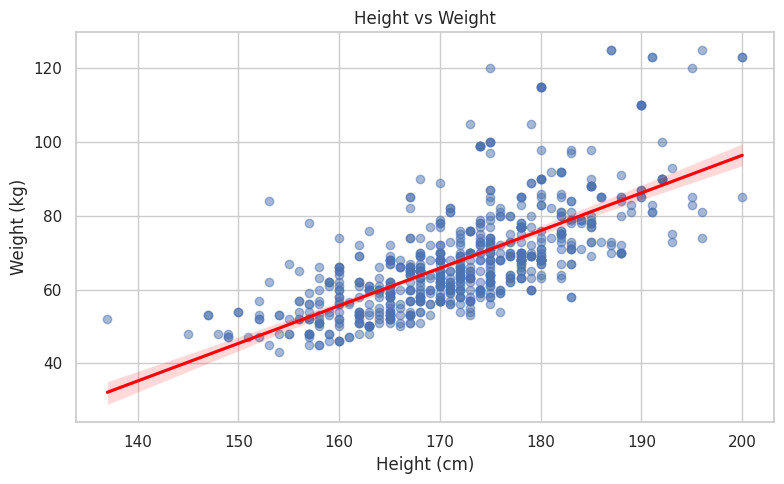

In [3]:
# Check the overall height-weight association and save the scatterplot.
correlation = df['Height'].corr(df['Weight'])
print(f'Pearson correlation (descriptive): {correlation:.3f}')
fig, ax = plt.subplots(figsize=(8, 5))
sns.regplot(data=df, x='Height', y='Weight',
            scatter_kws={'alpha': 0.5}, line_kws={'color': 'red'}, ax=ax)
ax.set(title='Height vs Weight', xlabel='Height (cm)', ylabel='Weight (kg)')
fig.tight_layout()
fig.savefig(PLOT_DIR / '01_height_weight_regression.png', dpi=200)
plt.show()

## 3. Height-only baseline OLS

Fit by ordinary least squares and report the equation and R², without cluster-robust inference or additional coefficient-level hypothesis tests.

In [4]:
# Start with height alone to get a simple benchmark for the later model.
baseline_all = smf.ols('Weight ~ Height', data=df).fit()
print(f'Estimated weight = {baseline_all.params["Intercept"]:.3f} '
      f'+ ({baseline_all.params["Height"]:.3f}) × Height')
print(f'R² (in sample): {baseline_all.rsquared:.3f}')

Estimated weight = -107.782 + (1.021) × Height
R² (in sample): 0.487


## 4. Extended multiple linear regression

Use sex and sports archetype as categorical predictors. A **height-by-archetype interaction** allows a different height slope for each archetype. Height is centered so the archetype intercept differences refer to average height. Sex has no interaction here, so its coefficient is assumed constant across archetypes.

In [5]:
# Keep clear single-archetype records for comparisons across sports groups.
df_model = df.loc[df['Archetype'] != 'MULTIPLE_ARCHETYPES'].copy()

# Centre height so archetype effects are compared at the average height.
df_model['Height_c'] = df_model['Height'] - df_model['Height'].mean()
FORMULA = (
    'Weight ~ Height_c * C(Archetype, Treatment(reference="Endurance"))'
    ' + C(Sex, Treatment(reference="M"))'
)

# Fit both models on the same records for a fair in-sample comparison.
model1_common = smf.ols('Weight ~ Height', data=df_model).fit()
model2 = smf.ols(FORMULA, data=df_model).fit()
print('Common-sample observations:', len(df_model))
print('Intercept and coefficient estimates (extended model):')
display(model2.params.rename('Estimate').to_frame().round(4))
print('In-sample R²: baseline =', round(model1_common.rsquared, 3),
      '; extended =', round(model2.rsquared, 3))

Common-sample observations: 727
Intercept and coefficient estimates (extended model):


,Estimate
Intercept,61.3786
"C(Archetype, Treatment(reference=""Endurance""))[T.Combat]",10.4734
"C(Archetype, Treatment(reference=""Endurance""))[T.Precision]",11.3638
"C(Archetype, Treatment(reference=""Endurance""))[T.Racket Sports]",7.6033
"C(Archetype, Treatment(reference=""Endurance""))[T.Speed & Power]",9.5477
"C(Archetype, Treatment(reference=""Endurance""))[T.Team Sports]",5.1148
"C(Archetype, Treatment(reference=""Endurance""))[T.Technical / Mixed]",5.0475
"C(Sex, Treatment(reference=""M""))[T.F]",-3.8273
Height_c,0.8860
"Height_c:C(Archetype, Treatment(reference=""Endurance""))[T.Combat]",0.3315


In-sample R²: baseline = 0.487 ; extended = 0.576


In [6]:
# Add each archetype's interaction to the Endurance slope to get its fitted slope.
ref_slope = model2.params['Height_c']
slopes = {}
for archetype in sorted(df_model['Archetype'].unique()):
    term = f'Height_c:C(Archetype, Treatment(reference="Endurance"))[T.{archetype}]'
    slopes[archetype] = ref_slope + model2.params.get(term, 0.0)
print('Height slopes by archetype (kg per cm):')
display(pd.Series(slopes, name='kg per cm').round(3).to_frame())

Height slopes by archetype (kg per cm):


,kg per cm
Combat,1.217
Endurance,0.886
Precision,1.017
Racket Sports,0.707
Speed & Power,1.261
Team Sports,0.613
Technical / Mixed,0.701


## 5. Hypothesis test: Do height–weight slopes differ by archetype?

We test whether allowing **Height × Archetype** interactions adds explanatory power after accounting for height, sex, and archetype main effects.

- **Null hypothesis (H₀):** All six height-by-archetype interaction coefficients equal zero (all archetypes share the same height slope).
- **Alternative hypothesis (H₁):** At least one interaction coefficient is nonzero (some archetypes have different height slopes).
- **Method:** Nested-model partial **F-test**, using ordinary least squares on the **same observations**.
- **Decision rule:** At significance level α = 0.05, reject H₀ when p < 0.05.

This is the one formal hypothesis test retained because it directly answers Checkpoint 1 Question 2. Interpret results as associations, not causal effects. Ordinary OLS F-test assumptions may be imperfect for repeated athlete-year observations.

In [7]:
from statsmodels.stats.anova import anova_lm

# Compare a model with one shared height slope against the model with archetype-specific slopes.
reduced_model = smf.ols(
    'Weight ~ Height_c + C(Archetype, Treatment(reference="Endurance"))'
    ' + C(Sex, Treatment(reference="M"))',
    data=df_model
).fit()

# Both models use the same rows, so the comparison is valid.
assert np.array_equal(reduced_model.model.data.row_labels, model2.model.data.row_labels)
interaction_test = anova_lm(reduced_model, model2)
print('Nested OLS F-test: height-by-archetype interactions')
display(interaction_test.round(6))
p_value = interaction_test['Pr(>F)'].iloc[1]
f_value = interaction_test['F'].iloc[1]
print(f'F = {f_value:.4f}; p = {p_value:.6g}; alpha = 0.05')
if p_value < 0.05:
    print('Reject H₀: evidence that height–weight slopes differ by archetype, controlling for sex.')
else:
    print('Fail to reject H₀: insufficient evidence that height–weight slopes differ by archetype.')

Nested OLS F-test: height-by-archetype interactions


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,718.0,64182.058703,0.0,NaN,NaN,NaN
1,712.0,59470.250520,6.0,4711.808183,9.401921,0.0


F = 9.4019; p = 6.01466e-10; alpha = 0.05
Reject H₀: evidence that height–weight slopes differ by archetype, controlling for sex.


## 6. Residual patterns and Q–Q plots

,count,mean,median,std
Archetype,,,,
Endurance,52,-7.27,-7.98,4.88
Technical / Mixed,28,-2.55,-3.83,7.44
Racket Sports,61,-1.67,0.10,7.42
Team Sports,245,-1.50,-1.88,6.53
Speed & Power,134,1.29,-1.15,12.08
Combat,110,3.36,1.15,11.29
Precision,97,3.87,1.08,12.74


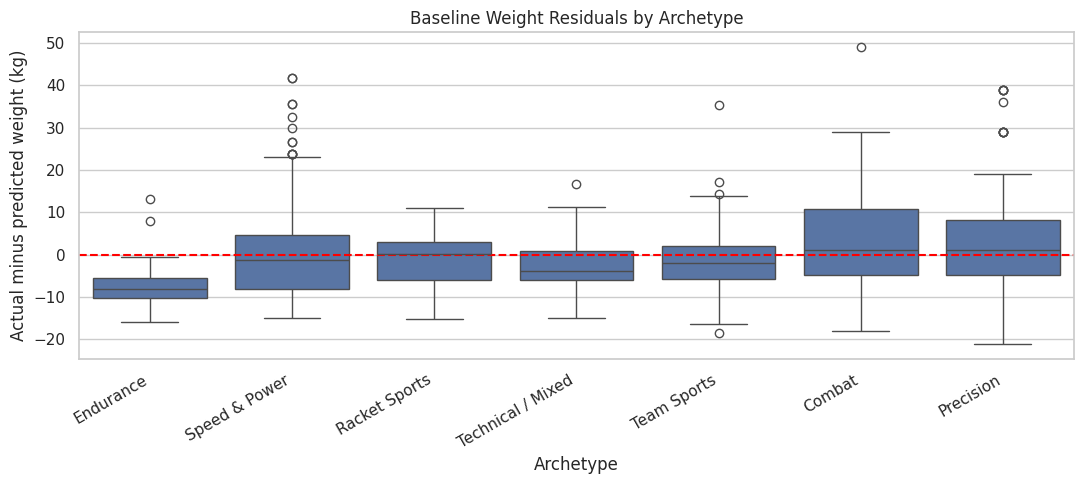

In [8]:
# Residual = actual weight minus the height-only model's prediction.
# Summarise these differences by archetype, then compare their distributions.
df_model['Baseline_Predicted'] = model1_common.predict(df_model)
df_model['Baseline_Residual'] = df_model['Weight'] - df_model['Baseline_Predicted']
residual_summary = (df_model.groupby('Archetype')['Baseline_Residual']
                    .agg(['count', 'mean', 'median', 'std'])
                    .sort_values('mean'))
display(residual_summary.round(2))

fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=df_model, x='Archetype', y='Baseline_Residual', ax=ax)
ax.axhline(0, color='red', linestyle='--')
ax.set(title='Baseline Weight Residuals by Archetype',
       xlabel='Archetype', ylabel='Actual minus predicted weight (kg)')
plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
fig.tight_layout()
fig.savefig(PLOT_DIR / '02_residuals_by_archetype.png', dpi=200)
plt.show()

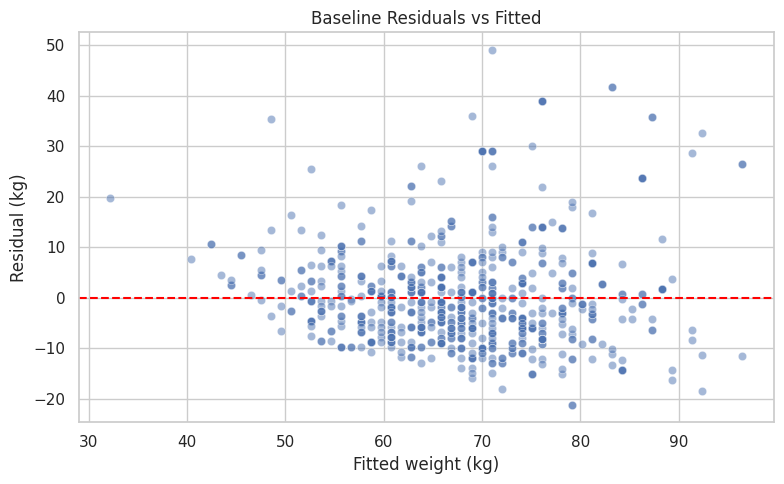

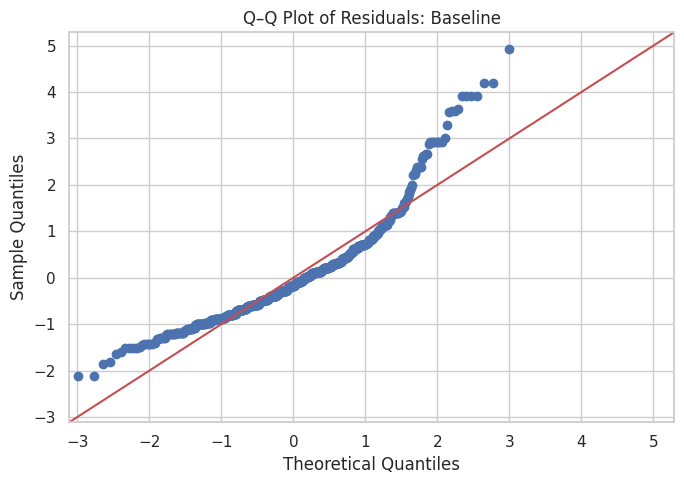

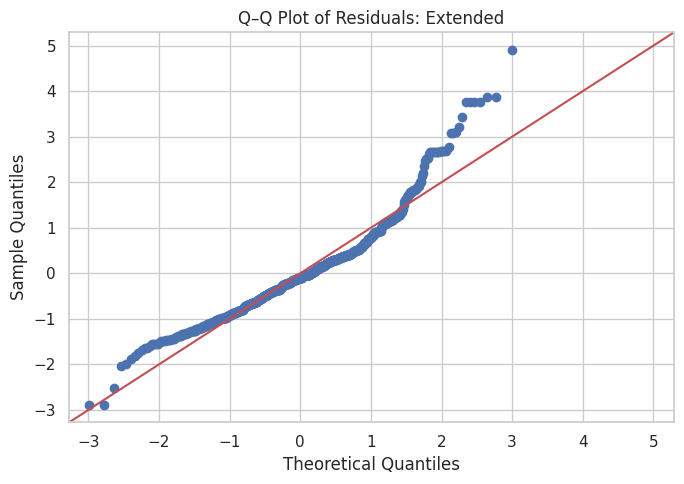

In [ ]:
# Check whether the baseline model errors show a pattern or uneven spread.
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(x=model1_common.fittedvalues, y=model1_common.resid, alpha=0.5, ax=ax)
ax.axhline(0, color='red', linestyle='--')
ax.set(title='Baseline Residuals vs Fitted',
       xlabel='Fitted weight (kg)', ylabel='Residual (kg)')
fig.tight_layout()
fig.savefig(PLOT_DIR / '03_baseline_residuals_vs_fitted.png', dpi=200)
plt.show()

# Q-Q plots help us see how closely the residuals follow a normal distribution.
for name, model, filename in [
    ('Baseline', model1_common, '04_baseline_qq.png'),
    ('Extended', model2, '05_extended_qq.png')
]:
    fig, ax = plt.subplots(figsize=(7, 5))
    sm.qqplot(model.resid, line='45', fit=True, ax=ax)
    ax.set_title(f'Q–Q Plot of Residuals: {name}')
    fig.tight_layout()
    fig.savefig(PLOT_DIR / filename, dpi=200)
    plt.show()

## 7. Athlete-grouped 80:20 train/test split

A seeded NumPy shuffle assigns approximately 20% of unique athlete IDs to the test partition (all records of each athlete stay together). The same athlete ID never appears in both partitions. We keep actual-versus-predicted comparisons, but **do not compute MAE, RMSE, or test R²**. Height is centered using the **training-set mean** only.

In [ ]:
# Split by athlete ID so the same athlete cannot appear in both sets.
# This gives a more realistic check on predictions for athletes not used in training.
rng = np.random.default_rng(42)
athlete_ids = df_model['ID'].unique()
shuffled_ids = rng.permutation(athlete_ids)
n_test = int(np.ceil(0.20 * len(shuffled_ids)))
test_ids = set(shuffled_ids[:n_test])
is_test = df_model['ID'].isin(test_ids)
train = df_model.loc[~is_test].copy()
test = df_model.loc[is_test].copy()
assert set(train['ID']).isdisjoint(set(test['ID']))

# Use the training-set average height for both sets to avoid using test information.
height_mean = train['Height'].mean()
train['Height_c'] = train['Height'] - height_mean
test['Height_c'] = test['Height'] - height_mean

# Refit both models using training records only, then predict the held-out athletes.
baseline_train = smf.ols('Weight ~ Height', data=train).fit()
extended_train = smf.ols(FORMULA, data=train).fit()

print(f'Train: {len(train)} rows / {train["ID"].nunique()} athletes')
print(f'Test:  {len(test)} rows / {test["ID"].nunique()} athletes')

comparison = test[['ID', 'Year', 'Height', 'Weight', 'Archetype', 'Sex']].copy()
comparison['Baseline_Predicted'] = baseline_train.predict(test).to_numpy()
comparison['Extended_Predicted'] = extended_train.predict(test).to_numpy()
comparison['Baseline_Residual'] = comparison['Weight'] - comparison['Baseline_Predicted']
comparison['Extended_Residual'] = comparison['Weight'] - comparison['Extended_Predicted']
print('First 20 held-out athlete-year predictions:')
display(comparison.head(20).round(2))
comparison.to_csv(OUTPUT_DIR / 'q2_test_predictions.csv', index=False)

Train: 580 rows / 416 athletes
Test:  147 rows / 105 athletes
First 20 held-out athlete-year predictions:


,ID,Year,Height,Weight,Archetype,Sex,Baseline_Predicted,Extended_Predicted,Baseline_Residual,Extended_Residual
2,512,1992,167.0,53.0,Endurance,F,62.80,53.23,-9.80,-0.23
3,512,1996,167.0,53.0,Speed & Power,F,62.80,61.43,-9.80,-8.43
27,6469,2016,165.0,52.0,Combat,F,60.73,59.26,-8.73,-7.26
41,8458,1972,178.0,75.0,Technical / Mixed,M,74.21,68.00,0.79,7.00
47,11197,1976,174.0,68.0,Team Sports,M,70.06,67.79,-2.06,0.21
48,11197,1980,174.0,68.0,Team Sports,M,70.06,67.79,-2.06,0.21
65,11637,2004,172.0,61.0,Speed & Power,M,67.99,71.69,-6.99,-10.69
71,12465,2004,175.0,62.0,Speed & Power,F,71.10,71.87,-9.10,-9.87
72,12465,2008,175.0,62.0,Speed & Power,F,71.10,71.87,-9.10,-9.87
73,13373,2012,190.0,87.0,Racket Sports,M,86.64,79.64,0.36,7.36


## 8. Individual 95% prediction intervals

These are **conventional ordinary least-squares observation-level prediction intervals**, not confidence intervals for the mean and not cluster-adjusted. Residual non-normality and changing residual spread may affect their nominal coverage.

In [11]:
# Calculate 95% prediction intervals for individual held-out records.
# These are ordinary OLS intervals, not cluster-adjusted intervals.
base_pi = baseline_train.get_prediction(test).summary_frame(alpha=0.05)
ext_pi = extended_train.get_prediction(test).summary_frame(alpha=0.05)
comparison['Baseline_95PI_Lower'] = base_pi['obs_ci_lower'].to_numpy()
comparison['Baseline_95PI_Upper'] = base_pi['obs_ci_upper'].to_numpy()
comparison['Extended_95PI_Lower'] = ext_pi['obs_ci_lower'].to_numpy()
comparison['Extended_95PI_Upper'] = ext_pi['obs_ci_upper'].to_numpy()
print('First 20 test predictions and individual 95% prediction intervals:')
display(comparison.head(20).round(2))
comparison.to_csv(OUTPUT_DIR / 'q2_test_predictions_with_intervals.csv', index=False)
print(f'Saved tables to: {OUTPUT_DIR.resolve()}')
print(f'Saved plots to:  {PLOT_DIR.resolve()}')

First 20 test predictions and individual 95% prediction intervals:


,ID,Year,Height,Weight,Archetype,Sex,Baseline_Predicted,Extended_Predicted,Baseline_Residual,Extended_Residual,Baseline_95PI_Lower,Baseline_95PI_Upper,Extended_95PI_Lower,Extended_95PI_Upper
2,512,1992,167.0,53.0,Endurance,F,62.80,53.23,-9.80,-0.23,42.33,83.28,34.28,72.17
3,512,1996,167.0,53.0,Speed & Power,F,62.80,61.43,-9.80,-8.43,42.33,83.28,42.83,80.04
27,6469,2016,165.0,52.0,Combat,F,60.73,59.26,-8.73,-7.26,40.25,81.21,40.50,78.02
41,8458,1972,178.0,75.0,Technical / Mixed,M,74.21,68.00,0.79,7.00,53.73,94.68,48.78,87.23
47,11197,1976,174.0,68.0,Team Sports,M,70.06,67.79,-2.06,0.21,49.59,90.53,49.27,86.32
48,11197,1980,174.0,68.0,Team Sports,M,70.06,67.79,-2.06,0.21,49.59,90.53,49.27,86.32
65,11637,2004,172.0,61.0,Speed & Power,M,67.99,71.69,-6.99,-10.69,47.52,88.45,53.09,90.30
71,12465,2004,175.0,62.0,Speed & Power,F,71.10,71.87,-9.10,-9.87,50.63,91.56,53.25,90.50
72,12465,2008,175.0,62.0,Speed & Power,F,71.10,71.87,-9.10,-9.87,50.63,91.56,53.25,90.50
73,13373,2012,190.0,87.0,Racket Sports,M,86.64,79.64,0.36,7.36,66.12,107.17,60.61,98.67


Saved tables to: /mnt/data/q2_outputs
Saved plots to:  /mnt/data/q2_outputs/plots


## 9. Interpretation and limitations

- The correlation is positive; height is useful but does not fully explain athlete weight.
- Compare the fitted height slopes to describe differences between sports archetypes after accounting for sex.
- Archetypes group different sports/events, so the estimates describe broad categories, not every sport separately.
- The model is observational: associations are not causal effects.
- The same athlete can appear in different Olympic years; the group-based holdout prevents athlete overlap across train and test, but the full-sample OLS fit does not independently model repeated measures.
- The intervals are conventional OLS individual prediction intervals; treat them cautiously if residual spread is nonconstant or tails depart from normality.

- Interpret the nested-model interaction F-test at α = 0.05 to answer whether slopes differ across archetypes.
